# 01b. Error analysis of in-context learning

Which senses does the best ICL configuration get wrong, and why? Runs on CPU from the prediction files written by
`01_icl` (no model needed). Figures go to `results/figures/`.

In [1]:
# Setup: on Colab or Kaggle, clone (or update) the repository so that `src/` is importable; locally, run from the repo root.
import os, sys
REPO_URL = "https://github.com/Alhassliebe/LAB1_classification_with_llms.git"
ON_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ
if "google.colab" in sys.modules or ON_KAGGLE:
    REPO_DIR = ("/kaggle/working" if ON_KAGGLE else "/content") + "/LAB1_classification_with_llms"
    if not os.path.exists(REPO_DIR):
        !git clone -q {REPO_URL} {REPO_DIR}
    else:
        !git -C {REPO_DIR} pull -q
    os.chdir(REPO_DIR)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

In [2]:
import re

import matplotlib.pyplot as plt
import pandas as pd

from src.data import SUPER2HYPER, SUPERSENSES, get_split, load_data
from src.evaluate import RESULTS_DIR, evaluate, plot_confusion

FIG_DIR = RESULTS_DIR / "figures"
metrics = pd.read_csv(RESULTS_DIR / "metrics.csv")
icl_dev = metrics[(metrics["method"] == "icl") & (metrics["split"] == "rand-dev")].drop_duplicates("config_id", keep="last")
BEST = icl_dev.sort_values("macro_f1_super").iloc[-1]["config_id"]
print("Best configuration on rand-dev:", BEST)


def load_preds(config_id, split="rand-dev"):
    """Prediction file of one ICL run, with a column telling whether the supersense is correct."""
    preds = pd.read_csv(RESULTS_DIR / "predictions" / f"icl__{config_id}__{split}.csv", keep_default_na=False)
    return preds.assign(correct=preds["gold_supersense"] == preds["pred_supersense"])


preds = load_preds(BEST)
train = get_split(load_data(), "train")

Best configuration on rand-dev: en_5shot_similar_nolemma_logprob


## 1. Which classes are hard? Per-class F1 vs frequency in train

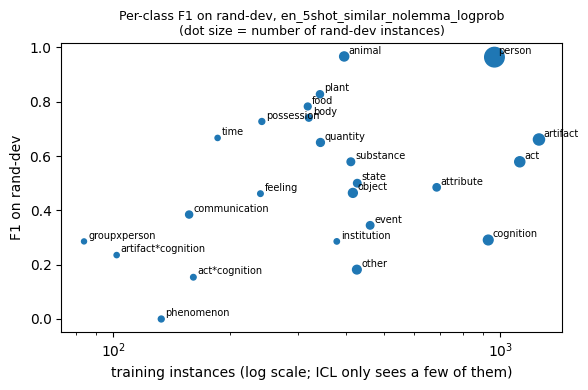

,f1,n_dev,n_train
phenomenon,0.0000,6,133
act*cognition,0.1538,4,161
other,0.1818,27,426
artifact*cognition,0.2353,2,102
institution,0.2857,3,378
groupxperson,0.2857,1,84
cognition,0.2909,37,931
event,0.3448,17,461
communication,0.3846,14,157
feeling,0.4615,4,240


In [3]:
scores = evaluate(preds["gold_supersense"].tolist(), preds["pred_supersense"].tolist(), SUPERSENSES)
per_class = pd.DataFrame({"f1": scores["per_class"]}).assign(
    n_dev=preds["gold_supersense"].value_counts(), n_train=train["supersense"].value_counts()).sort_values("f1")

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(per_class["n_train"], per_class["f1"], s=12 + per_class["n_dev"])
for label, row in per_class.iterrows():
    ax.annotate(label, (row["n_train"], row["f1"]), fontsize=7, xytext=(3, 2), textcoords="offset points")
ax.set_xscale("log")
ax.set_xlabel("training instances (log scale; ICL only sees a few of them)")
ax.set_ylabel("F1 on rand-dev")
ax.set_title(f"Per-class F1 on rand-dev, {BEST}\n(dot size = number of rand-dev instances)", fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "icl_per_class_f1.png", dpi=200)
plt.show()
per_class

## 2. Confusions

In [4]:
plot_confusion(preds["gold_supersense"].tolist(), preds["pred_supersense"].tolist(), SUPERSENSES,
               FIG_DIR / "icl_confusion_supersense.png")
errors = preds[~preds["correct"]]
errors.groupby(["gold_supersense", "pred_supersense"]).size().sort_values(ascending=False).head(15).to_frame("n")

,,n
gold_supersense,pred_supersense,
cognition,artifact,8
artifact,object,8
object,substance,7
cognition,artifact*cognition,6
substance,artifact,5
cognition,communication,4
person,other,4
phenomenon,event,4
communication,other,3


## 3. Are errors near misses?

An error is *within hypersense* when the predicted supersense has the same hypersense as the gold one
(e.g. *act* → *event*, both *dynamic_situation*).

In [5]:
same_hyper = errors["pred_supersense"].map(SUPER2HYPER) == errors["gold_hypersense"]
print(f"{len(errors)} errors: {same_hyper.mean():.0%} within the gold hypersense, "
      f"{(~same_hyper).mean():.0%} across hypersenses")
print(f"Supersense accuracy {preds['correct'].mean():.3f}  vs  hypersense accuracy "
      f"{(preds['gold_hypersense'] == preds['pred_hypersense']).mean():.3f}")

185 errors: 27% within the gold hypersense, 73% across hypersenses
Supersense accuracy 0.675  vs  hypersense accuracy 0.763


## 4. Which inputs are hard? Error rate by property of the definition

In [6]:
# Same shallow cues as in 00_data_exploration.
props = preds.assign(
    n_words=preds["definition"].str.split().str.len(),
    demonym=preds["definition"].str.match(r"Habitant|Habitante", flags=re.I),
    synonym_or_variant=preds["definition"].str.match(r"(Synonyme|Variante|Autre nom|Pluriel) de", flags=re.I),
    complex_type=preds["gold_supersense"].str.contains("*", regex=False),
)
props["length"] = pd.cut(props["n_words"], [-1, 3, 7, 15, 1000], labels=["0-3", "4-7", "8-15", ">15"])
rows = [(name, value, len(group), 1 - group["correct"].mean())
        for name in ["length", "demonym", "synonym_or_variant", "complex_type"]
        for value, group in props.groupby(name, observed=True)]
pd.DataFrame(rows, columns=["property", "value", "n", "error_rate"]).round(3)

,property,value,n,error_rate
0,length,0-3,71,0.423
1,length,4-7,138,0.377
2,length,8-15,240,0.254
3,length,>15,121,0.347
4,demonym,False,457,0.405
5,demonym,True,113,0.000
6,synonym_or_variant,False,547,0.322
7,synonym_or_variant,True,23,0.391
8,complex_type,False,564,0.323
9,complex_type,True,6,0.500


## 5. What does the lemma change?

Senses classified correctly only with the lemma, and only without it, in the two runs of the lemma comparison.

In [7]:
# The configuration of the lemma comparison (stage 4 of 01_icl): the only pair of runs that differ by the lemma.
LEMMA_ID = next(c for c in icl_dev["config_id"] if c.endswith("_lemma")
                and c.replace("_lemma", "_nolemma") in set(icl_dev["config_id"]))
both = load_preds(LEMMA_ID).merge(load_preds(LEMMA_ID.replace("_lemma", "_nolemma"))[
    ["sense_id", "pred_supersense", "correct"]], on="sense_id", suffixes=("", "_nolemma"))
helped = both[both["correct"] & ~both["correct_nolemma"]]
hurt = both[~both["correct"] & both["correct_nolemma"]]
print(f"{LEMMA_ID}: the lemma fixes {len(helped)} senses and breaks {len(hurt)}")
display(helped[["lemma", "definition", "gold_supersense", "pred_supersense_nolemma"]].head(10))
display(hurt[["lemma", "definition", "gold_supersense", "pred_supersense"]].head(10))

en_5shot_similar_lemma: the lemma fixes 24 senses and breaks 45


,lemma,definition,gold_supersense,pred_supersense_nolemma
11,flux,"Transfert de biens, de service, d’argent ou de...",event,act
53,terpan,Surélévation artificielle du sol où sont const...,artifact,object
71,âge_nubile,Âge à partir duquel on a la possibilité de se ...,attribute,quantity
79,chablis,Synonyme de chardonnay blanc.,plant,food
81,masturbé,"Celui qui est, ou qui s’est masturbé.",person,feeling
144,ajustabilité,"Le fait de pouvoir ajuster, déplacer dans une ...",attribute,act
188,question_préjudicielle,Question qui doit être jugée avant la contesta...,act*cognition,act
235,fosse_aux_ours,Enclos creusé en profondeur pour maintenir des...,artifact,object
254,vagabondage,Délit de toute personne qui n’a ni domicile ce...,act,person
259,modernité,"Ce qui est désigné comme moderne, nouveau, inn...",attribute,artifact


,lemma,definition,gold_supersense,pred_supersense
13,vergobret,Magistrat suprême de certaines cités gauloises.,person,institution
19,théâtre_d’ombres,Situation dans laquelle l’on ne sait pas qui e...,state,
34,sigmatisme_nasal,Passage d’une partie de l’air dans le nez lors...,event,feeling
41,roidissage,Variante de raidissage → voir roidir.,other,artifact
51,inconséquent,Personnage qui fait preuve d’inconséquence.,person,feeling
54,pilule_rouge,L’une de ces mêmes vérités ou pseudo-vérités.,cognition,artifact*cognition
60,craillon,Dette criarde.,possession,act
61,bébé_adulte,Adulte ayant l’apparence physique d’un bébé.,person,state
95,préimprégné_en_feuille,Préimprégné destiné à être mis en œuvre par co...,substance,artifact
97,ilienne,Habitante d’une ile.,person,other


## 6. Errors to read by hand

In [8]:
pd.set_option("display.max_colwidth", 90)
errors.sample(min(30, len(errors)), random_state=42)[["lemma", "definition", "gold_supersense", "pred_supersense", "raw_output"]]

,lemma,definition,gold_supersense,pred_supersense,raw_output
79,chablis,Synonyme de chardonnay blanc.,plant,food,food -0.67 | plant -0.75 | substance -4.73
153,double_pied_de_nez,Geste de moquerie consistant à faire un pied de nez avec ses deux mains.,act,act*cognition,act*cognition -0.48 | act -0.97 | other -11.20
521,cellule,"Élément fonctionnel d’une machine, d’un ordinateur, etc.",cognition,artifact,artifact -0.00 | artifact*cognition -9.30 | object -10.11
384,idéophonogramme,"Sinogramme composé de deux caractères plus simples, l’un pour le radical de la catégor...",communication,artifact*cognition,artifact*cognition -0.31 | artifact -2.42 | other -2.54
506,sergetterie,Sergerie.,act,other,other -0.47 | artifact -1.76 | artifact*cognition -1.90
71,âge_nubile,Âge à partir duquel on a la possibilité de se marier.,attribute,state,state -0.56 | quantity -1.56 | attribute -3.08
98,tournée,"Ensemble des consommations des personnes réunies autour d’une même table de café, que ...",other,quantity,quantity -0.69 | act -1.39 | artifact -1.72
245,cellule,Élément fondamental d’un motif musical.,cognition,artifact*cognition,artifact*cognition -0.24 | cognition -1.80 | object -3.25
405,hormogonie,"Fragment pluricellulaire d’un filament d’un thalle de Cyanobactérie, forme de multipli...",object,act,act -0.84 | object -1.29 | artifact -1.67
333,ta_marbouta,"ةVariante de tāʾ marbūṭa, lettre arabe ة.",communication,other,other -0.00 | artifact -5.92 | object -7.63


## 7. Test sets

In [9]:
for split in ["rand-test", "freq-test"]:
    test_ids = metrics[(metrics["method"] == "icl") & (metrics["split"] == split)]["config_id"]
    if len(test_ids):
        test = load_preds(test_ids.iloc[-1], split)
        s = evaluate(test["gold_supersense"].tolist(), test["pred_supersense"].tolist(), SUPERSENSES)
        worst = sorted(s["per_class"].items(), key=lambda kv: kv[1])[:5]
        print(f"{split}: macro-F1 {s['macro_f1']:.3f}, accuracy {s['accuracy']:.3f}; worst classes {worst}")
        plot_confusion(test["gold_supersense"].tolist(), test["pred_supersense"].tolist(), SUPERSENSES,
                       FIG_DIR / f"icl_confusion_{split}.png")

rand-test: macro-F1 0.583, accuracy 0.717; worst classes [('act*cognition', 0.0), ('other', 0.1176), ('phenomenon', 0.2222), ('relation', 0.2222), ('object', 0.4561)]
freq-test: macro-F1 0.519, accuracy 0.523; worst classes [('relation', 0.0741), ('other', 0.1238), ('communication', 0.2182), ('act*cognition', 0.2353), ('event', 0.3191)]


## Observations

- Demonyms (*Habitant de …*) are almost always right (0 errors among the 113 of `rand-dev`); they make up a sixth of
  `rand-*` and inflate its accuracy. Without them, `rand-test` accuracy falls from 0.717 to 0.66.
- The weakest classes are the residual `other` (F1 0.12 on both test sets), the complex types (`act*cognition`
  0.00 on `rand-test`, 0.24 on `freq-test`), `relation` and `phenomenon`: classes defined by a contrast with other
  classes rather than by a property the definition states.
- Most errors are not near misses (19–27 % stay inside the gold hypersense). The most frequent ones cross a fuzzy
  boundary: `artifact` vs `object` (man-made or not), `act` vs `event` (agent or not), `act` vs `act*cognition`,
  `cognition` vs `artifact*cognition` (content vs carrier).
- Short definitions (1–3 words, often a synonym) are the hardest; with the lemma the model also over-reacts to rare
  or multiword lemmas, which is why the final configuration leaves it out.